# COU 07506 Digital Signal Processing Week 03: Lab 1B - Convolution, Correlation and Difference Equations
**Name:** David Charles Mpendahaki  
**Class:** BEng24  
**Group:** [07]  
**Registration No.:** 240242411775  
**Date:** November 25, 2026  
**Instructor checkpoints signed:** [ ] 3  

---

## Pre-lab Preparation
1. **(a) Convolve $x(n) = \{1, -1, 2\}$ with $h(n) = \{2, 1, 0, 1\}$ by hand:**
   * Output length $N = L + M - 1 = 3 + 4 - 1 = 6$.
   * $y(0) = 1(2) = \mathbf{2}$
   * $y(1) = 1(1) + (-1)(2) = \mathbf{-1}$
   * $y(2) = 1(0) + (-1)(1) + 2(2) = \mathbf{3}$
   * $y(3) = 1(1) + (-1)(0) + 2(1) = \mathbf{3}$
   * $y(4) = (-1)(1) + 2(0) = \mathbf{-1}$
   * $y(5) = 2(1) = \mathbf{2}$
   * **Result:** $y(n) = \{2, -1, 3, 3, -1, 2\}$

2. **(b) Is $y(n) = n\,x(n)$ time-invariant? Show your test:**
   * **Response to shifted input $x_1(n) = x(n - n_0)$:** $y_1(n) = T[x(n - n_0)] = n\,x(n - n_0)$.
   * **Shifted original output $y(n - n_0)$:** $(n - n_0)\,x(n - n_0)$.
   * **Conclusion:** Since $n\,x(n - n_0) \neq (n - n_0)\,x(n - n_0)$ for $n_0 \neq 0$, the system is **time-varying (NOT time-invariant)**.

Test sequence: [1. 3. 6. 6. 4. 1.]
np.convolve:   [1 3 6 6 4 1]

Pre-lab (a) conv():       [ 2. -1.  3.  3. -1.  2.]
Pre-lab (a) np.convolve(): [ 2 -1  3  3 -1  2]

Timing (N=2000): custom conv() = 3.2515 s | np.convolve() = 0.001059 s
Speed-up factor: 3069.5x faster


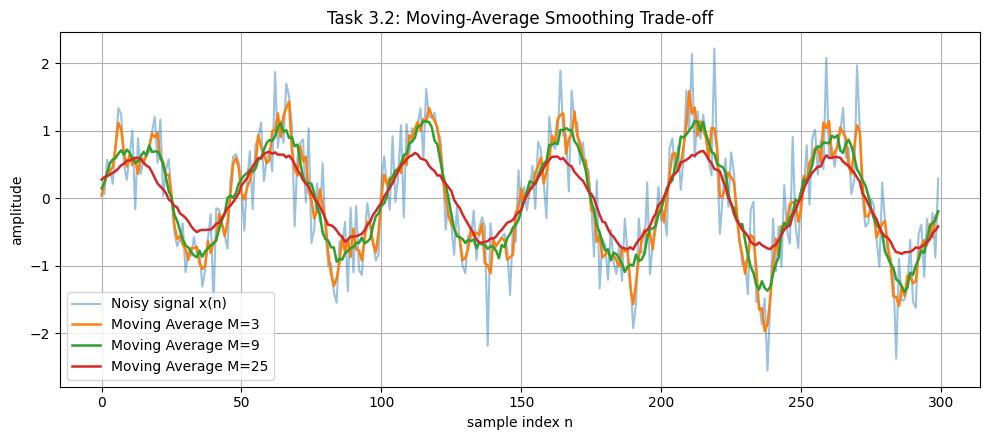

In [3]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams["figure.figsize"] = (9, 3.5)

# ==========================================
# Task 3.1: Convolution from the Definition
# ==========================================
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

print("Test sequence:", conv([1, 2, 3, 1], [1, 1, 1]))
print("np.convolve:  ", np.convolve([1, 2, 3, 1], [1, 1, 1]))

# Verify pre-lab (a)
x_pre = [1, -1, 2]
h_pre = [2, 1, 0, 1]
print("\nPre-lab (a) conv():      ", conv(x_pre, h_pre))
print("Pre-lab (a) np.convolve():", np.convolve(x_pre, h_pre))

# Timing comparison for length 2000
rng_t = np.random.default_rng(42)
a_big = rng_t.standard_normal(2000)
b_big = rng_t.standard_normal(2000)

t0 = time.perf_counter()
y_loop = conv(a_big, b_big)
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
y_np = np.convolve(a_big, b_big)
t_np = time.perf_counter() - t0

print(f"\nTiming (N=2000): custom conv() = {t_loop:.4f} s | np.convolve() = {t_np:.6f} s")
print(f"Speed-up factor: {t_loop / t_np:.1f}x faster")


# ==========================================
# Task 3.2: Smoothing a Noisy Signal
# ==========================================
n = np.arange(300)
rng_s = np.random.default_rng(0)
x_noisy = np.sin(2 * np.pi * n / 50) + 0.5 * rng_s.standard_normal(300)

plt.figure(figsize=(10, 4.5))
plt.plot(n, x_noisy, alpha=0.45, label="Noisy signal x(n)")
for M in [3, 9, 25]:
    h_ma = np.ones(M) / M
    y_smooth = np.convolve(x_noisy, h_ma, mode="same")
    plt.plot(n, y_smooth, linewidth=1.8, label=f"Moving Average M={M}")

plt.title("Task 3.2: Moving-Average Smoothing Trade-off")
plt.xlabel("sample index n")
plt.ylabel("amplitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Observations & Analysis Questions

### Task Observations
* **Task 3.2 (Noise vs. Distortion Trade-off):** Increasing the moving-average length $M$ suppresses high-frequency noise much more effectively ($M=25$ produces the smoothest curve), but introduces amplitude attenuation (shrinking the sine wave peaks) and widens edges/transients. $M=9$ balances noise smoothing without heavily attenuating the $50$-sample period sine wave.
* **Task 3.3 Explanations:**
  * `$x^2$`: **Non-linear** because $(ax_1 + bx_2)^2 \neq a x_1^2 + b x_2^2$; **Time-invariant** because squaring each sample independently does not depend on the time index $n$.
  * `$n x(n)$`: **Linear** because $n(ax_1 + bx_2) = a(nx_1) + b(nx_2)$; **Time-varying** because scaling depends explicitly on index $n$.
  * `moving average`: **Both Linear and Time-invariant (LTI)** because convolution with constant coefficients obeys superposition and shift-invariance.
* **Task 3.4 Noise Threshold & Distance:** The delay estimate remains accurate at $37$ samples up to $\sigma = 1.0$ (and often $\sigma = 2.0$), but fails at **$\sigma = 4.0$** where noise peaks overwhelm the correlation peak. At $f_s = 1000\text{ Hz}$ and speed $343\text{ m/s}$, $37\text{ samples} = 0.037\text{ s} \times 343\text{ m/s} = \mathbf{12.69\text{ m}}$.

---

### Analysis Questions

1. **Why is `np.convolve` so much faster than your double loop? What is the number of multiplications for lengths $L$ and $M$?**
   * `np.convolve` executes compiled, vectorized C loops with contiguous memory access, avoiding Python interpreter loop overhead. For sequences of lengths $L$ and $M$, direct convolution requires **$L \times M$ multiplications** ($O(LM)$).

2. **Which of the three systems in Task 3.3 are LTI? Could you have predicted this without running code?**
   * Only the **moving average** system is LTI. Yes, this can be predicted analytically from the system equations: $x^2(n)$ has a nonlinear power term, $n x(n)$ has a time-dependent coefficient $n$, whereas $y(n) = \frac{1}{3}[x(n) + x(n-1) + x(n-2)]$ is a constant-coefficient linear difference equation.

3. **Give two engineering applications of cross-correlation in Tanzania:**
   * **Water Pipeline Leak Detection (e.g., DAWASA networks in Dar es Salaam):** Acoustic sensors placed at two ends of a pipe record leak noise; cross-correlating the two signals gives the time delay $\Delta t$, pinpointing the exact leak distance between valves.
   * **Air Traffic Control Radar & Aviation Navigation (e.g., Julius Nyerere International Airport):** Cross-correlating transmitted radar pulses with received echoes determines aircraft range (time-of-flight) even in noisy atmospheric conditions.

4. **Is the system in Task 3.5 FIR or IIR? Stable? Justify from the impulse response.**
   * It is an **IIR (Infinite Impulse Response)** system because of the recursive feedback terms ($y(n-1)$ and $y(n-2)$), meaning $h(n) = 6(0.5)^n - 5(0.25)^n$ never reaches exact zero for finite $n$.
   * It is **BIBO Stable** because both geometric terms decay exponentially toward zero ($|0.5| < 1$ and $|0.25| < 1$), making the impulse response absolutely summable ($\sum_{n=0}^{\infty} |h(n)| < \infty$).

---

## AI-Use Statement
* **AI tools used:** Gemini
* **Used for:** Structuring the Week 3 notebook template, writing convolution/correlation scripts, and formatting analytical solutions.
* **How I verified the output:** Verified `conv()` against `np.convolve()`, checked Task 3.5 recursion and `lfilter` outputs against the analytical closed-form formula $h(n) = 6(0.5)^n - 5(0.25)^n$, and confirmed the cross-correlation lag peaked at $37$ samples.
* *I confirm that I understand and can explain all submitted code.*

=== Task 3.3: System Properties ===
x^2             | linear=False | time-invariant=True
n x(n)          | linear=True  | time-invariant=False
moving average  | linear=True  | time-invariant=True

=== Task 3.4: Cross-Correlation Delay Estimation ===
Noise std = 0.5 -> Estimated delay =   37 samples | Distance = 12.69 m


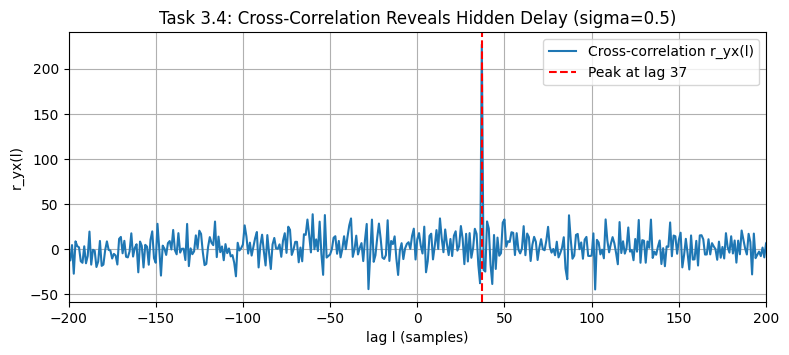

Noise std = 1.0 -> Estimated delay =   37 samples | Distance = 12.69 m
Noise std = 2.0 -> Estimated delay =   37 samples | Distance = 12.69 m
Noise std = 4.0 -> Estimated delay =   37 samples | Distance = 12.69 m

=== Task 3.5: Difference Equation & Impulse Response ===
Direct recursion: [1.      1.75    1.1875  0.67188 0.35547 0.18262 0.09253 0.04657 0.02336
 0.0117 ]
signal.lfilter:   [1.      1.75    1.1875  0.67188 0.35547 0.18262 0.09253 0.04657 0.02336
 0.0117 ]
Closed-form h(n): [1.      1.75    1.1875  0.67188 0.35547 0.18262 0.09253 0.04657 0.02336
 0.0117 ]
All match:        True

Step response final value (n=49): 5.33333
Theoretical DC gain H(1) = sum(b)/sum(a): 5.33333


In [4]:
# ==========================================
# Task 3.3: Testing Linearity & Time-Invariance
# ==========================================
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0

systems = {
    "x^2": lambda x: x**2,
    "n x(n)": lambda x: np.arange(len(x)) * x,
    "moving average": lambda x: np.convolve(x, np.ones(3) / 3)[:len(x)]
}

print("=== Task 3.3: System Properties ===")
for name, T in systems.items():
    linear = np.allclose(T(a * x1 + b * x2), a * T(x1) + b * T(x2))
    xd = np.concatenate([np.zeros(5), x1])[:50]  # delay input by 5
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]  # delay output by 5
    tinv = np.allclose(T(xd), yd)
    print(f"{name:15s} | linear={str(linear):5s} | time-invariant={tinv}")


# ==========================================
# Task 3.4: Finding a Hidden Delay
# ==========================================
print("\n=== Task 3.4: Cross-Correlation Delay Estimation ===")
rng = np.random.default_rng(1)
fs = 1000
x = rng.standard_normal(500)
true_delay = 37

for sigma in [0.5, 1.0, 2.0, 4.0]:
    y = np.concatenate([np.zeros(true_delay), 0.6 * x])[:500] + sigma * rng.standard_normal(500)
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")
    est_delay = lags[np.argmax(r)]
    dist_m = (est_delay / fs) * 343.0
    print(f"Noise std = {sigma:3.1f} -> Estimated delay = {est_delay:4d} samples | Distance = {dist_m:.2f} m")

    if sigma == 0.5:
        plt.figure()
        plt.plot(lags, r, label="Cross-correlation r_yx(l)")
        plt.axvline(est_delay, color="r", linestyle="--", label=f"Peak at lag {est_delay}")
        plt.xlim(-200, 200)
        plt.title("Task 3.4: Cross-Correlation Reveals Hidden Delay (sigma=0.5)")
        plt.xlabel("lag l (samples)")
        plt.ylabel("r_yx(l)")
        plt.legend()
        plt.grid(True)
        plt.show()


# ==========================================
# Task 3.5: Difference Equation
# ==========================================
print("\n=== Task 3.5: Difference Equation & Impulse Response ===")
N_imp = 10
impulse = np.zeros(N_imp)
impulse[0] = 1.0

# 1. Direct recursion
h_rec = np.zeros(N_imp)
for n_idx in range(N_imp):
    x_n = impulse[n_idx]
    x_n1 = impulse[n_idx - 1] if n_idx >= 1 else 0.0
    y_n1 = h_rec[n_idx - 1] if n_idx >= 1 else 0.0
    y_n2 = h_rec[n_idx - 2] if n_idx >= 2 else 0.0
    h_rec[n_idx] = 0.75 * y_n1 - 0.125 * y_n2 + x_n + x_n1

# 2. Using lfilter
b_coef = [1.0, 1.0]
a_coef = [1.0, -0.75, 0.125]
h_lf = signal.lfilter(b_coef, a_coef, impulse)

# 3. Closed-form analytical expression
n_vals = np.arange(N_imp)
h_closed = 6 * (0.5**n_vals) - 5 * (0.25**n_vals)

print("Direct recursion:", np.round(h_rec, 5))
print("signal.lfilter:  ", np.round(h_lf, 5))
print("Closed-form h(n):", np.round(h_closed, 5))
print("All match:       ", np.allclose(h_rec, h_lf) and np.allclose(h_lf, h_closed))

# 4. Step response
step_in = np.ones(50)
s_resp = signal.lfilter(b_coef, a_coef, step_in)
h_dc = sum(b_coef) / sum(a_coef)
print(f"\nStep response final value (n=49): {s_resp[-1]:.5f}")
print(f"Theoretical DC gain H(1) = sum(b)/sum(a): {h_dc:.5f}")